# GPU-accelerated conformer workflows with nvMolKit

**Note:** This is a guest post from Kevin Boyd at NVIDIA.

[nvMolKit](https://github.com/NVIDIA-BioNeMo/nvMolKit) is an open-source library
with GPU-accelerated, batched versions of common RDKit operations. The APIs stay
close to RDKit's, so in most cases you can swap a loop of RDKit calls for a
single nvMolKit call on the whole batch. Installation and API details are in the
[nvMolKit documentation](https://nvidia-bionemo.github.io/nvMolKit/).

Our [previous post](https://greglandrum.github.io/rdkit-blog/posts/2026-02-28-nvmolkit-clustering.html)
covered fingerprints, similarity, and clustering. This time we move to 3D, with a
workflow that will look familiar to anyone who has prepared conformers for
virtual screening or a 3D QSAR model:

1. **Generate conformers.** 50 ETKDGv3 conformers per molecule.
2. **Clean them up.** Minimize every conformer with MMFF94.
3. **Describe their shapes.** Calculate a set of 3D descriptors for every conformer.
4. **Remove redundant conformers.** Compute all-pairs torsion fingerprint
   deviation (TFD) matrices and use them to prune each ensemble.

We'll run each step with RDKit on the CPU and with nvMolKit on the GPU, check
that the two agree, and then compare timings at the end.

## Installation

nvMolKit is available on conda-forge alongside RDKit. It needs an NVIDIA GPU
with compute capability 7.0 (V100) or newer. Both packages can go into the same
environment:

```bash
conda install -c conda-forge rdkit nvmolkit jupyterlab
```

nvMolKit depends on PyTorch, and we also use it here to check that CUDA is available
and to synchronize the GPU before reading timers. conda normally picks a CUDA
build of PyTorch, but if `torch.cuda.is_available()` returns `False` in the next
cell, add `"pytorch=*=cuda*"` to the install command.

In [1]:
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from time import perf_counter
import gzip
import importlib.metadata
import multiprocessing
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from rdkit import Chem, rdBase
from rdkit.Chem import AllChem, rdDistGeom, rdMolDescriptors, TorsionFingerprints
from rdkit.ML.Cluster import Butina

from nvmolkit.descriptors3d import Calc3DProperties, Property3D
from nvmolkit.embedMolecules import EmbedMolecules
from nvmolkit.mmffOptimization import MMFFOptimizeMoleculesConfs
from nvmolkit.tfd import GetTFDMatrices
from nvmolkit.types import FireOptions, HardwareOptions, PrecisionMode

print("Python:", platform.python_version())
print("RDKit:", rdBase.rdkitVersion)
print("nvMolKit:", importlib.metadata.version("nvmolkit"))
print("PyTorch:", torch.__version__)
assert torch.cuda.is_available(), "CUDA is required for nvMolKit"
print("GPU:", torch.cuda.get_device_name(0))

Python: 3.14.10
RDKit: 2026.03.6
nvMolKit: 0.7.0
PyTorch: 2.14.1
GPU: NVIDIA GeForce RTX 5080


## Configuration

The timings below were collected on an NVIDIA GeForce RTX 5080 with an AMD Ryzen
9 9950X, limiting both RDKit and nvMolKit to 16 CPU threads. A random
1,000-molecule sample of Enamine REAL is included with this post. If you'd like
to try more molecules, the
[Enamine REAL 10.4M sample](https://enamine.net/compound-collections/real-compounds/real-database-subsets)
is a good place to start.

Both nvMolKit minimizers, BFGS and FIRE, are used with an iteration limit. We'll come back to
how the FIRE limit was chosen in the appendix.

In [2]:
# Number of molecules to process
n_mols = 1000

# Conformers to generate per molecule
n_confs = 50

# CPU threads for RDKit and for nvMolKit's CPU-side preprocessing
n_cpu_threads = 16

# Force-field iteration limits
max_mmff_iters = 200
fire_iters = 400

# ETKDG random seed
random_seed = 42

# Floating-point precision for the nvMolKit ETKDG and MMFF stages
gpu_precision = PrecisionMode.SINGLE

smi_file = Path("../data/enamine_real_1000.cxsmiles.gz")
assert smi_file.exists(), f"Enamine REAL file not found: {smi_file}"

hardware_options = HardwareOptions(preprocessingThreads=n_cpu_threads, gpuIds=[0])

### A note on precision

nvMolKit can run ETKDG and the force-field minimizers in either double
(`PrecisionMode.FULL`) or single (`PrecisionMode.SINGLE`) precision. Consumer
GPUs like the RTX 5080 have much higher single-precision than double-precision
throughput, and conformer generation and minimization don't need 15
significant digits. Here we use single precision for both stages. If you'd
rather match RDKit's arithmetic as closely as possible, set
`gpu_precision = PrecisionMode.FULL`; it's slower but still runs entirely on the
GPU.

## Loading molecules

The bundled sample contains 1,000 randomly selected molecules for which RDKit has
complete MMFF parameters. We parse the SMILES and add hydrogens. None of this
setup is included in the timings.

In [3]:
mols = []
with gzip.open(smi_file, "rt") as inf:
    next(inf)
    for line in inf:
        mol = Chem.MolFromSmiles(line.split("\t", 1)[0])
        if mol is None:
            continue
        mol = Chem.AddHs(mol)
        if not AllChem.MMFFHasAllMoleculeParams(mol):
            continue
        mols.append(mol)
        if len(mols) == n_mols:
            break

assert len(mols) == n_mols, f"Expected {n_mols:,} molecules, loaded {len(mols):,}"
print(f"Loaded {len(mols):,} molecules")
print(f"Median heavy atoms: {np.median([m.GetNumHeavyAtoms() for m in mols]):.0f}")

Loaded 1,000 molecules
Median heavy atoms: 26


## Step 1: ETKDG conformer generation

Both RDKit and nvMolKit generate 50 conformers per molecule with ETKDGv3,
random-coordinate initialization, and the same random seed. RDKit spreads each
molecule's 50 conformers over 16 CPU threads. nvMolKit takes the whole batch
of molecules at once and embeds all of them on the GPU.

Before timing anything, we make a couple of small untimed calls to get one-time
setup costs (CUDA context creation and so on) out of the way.

In [4]:
rd_params = rdDistGeom.ETKDGv3()
rd_params.useRandomCoords = True
rd_params.randomSeed = random_seed
rd_params.numThreads = n_cpu_threads

nv_params = rdDistGeom.ETKDGv3()
nv_params.useRandomCoords = True
nv_params.randomSeed = random_seed

rd_warmup = Chem.Mol(mols[0])
rdDistGeom.EmbedMultipleConfs(rd_warmup, numConfs=2, params=rd_params)
nv_warmup = [Chem.Mol(m) for m in mols[:4]]
EmbedMolecules(
    nv_warmup,
    nv_params,
    confsPerMolecule=2,
    hardwareOptions=hardware_options,
    precision=gpu_precision,
)
torch.cuda.synchronize()

In [5]:
rdkit_embedded = [Chem.Mol(m) for m in mols]
t0 = perf_counter()
for mol in rdkit_embedded:
    rdDistGeom.EmbedMultipleConfs(mol, numConfs=n_confs, params=rd_params)
rdkit_embed_time = perf_counter() - t0

rdkit_n_confs = sum(m.GetNumConformers() for m in rdkit_embedded)
print(f"RDKit ETKDG: {rdkit_embed_time:.2f} s ({rdkit_n_confs:,} conformers)")

RDKit ETKDG: 111.15 s (49,950 conformers)


In [6]:
nvmolkit_embedded = [Chem.Mol(m) for m in mols]
t0 = perf_counter()
EmbedMolecules(
    nvmolkit_embedded,
    nv_params,
    confsPerMolecule=n_confs,
    hardwareOptions=hardware_options,
    precision=gpu_precision,
)
torch.cuda.synchronize()
nvmolkit_embed_time = perf_counter() - t0

nvmolkit_n_confs = sum(m.GetNumConformers() for m in nvmolkit_embedded)
print(f"nvMolKit ETKDG: {nvmolkit_embed_time:.2f} s ({nvmolkit_n_confs:,} conformers)")

nvMolKit ETKDG: 19.59 s (49,950 conformers)

ETKDG can occasionally fail to embed a molecule at all. To keep the
comparisons below one-to-one, we drop any molecule that either implementation
failed to embed.

In [7]:
embedded_both = [
    i
    for i, (rd, nv) in enumerate(zip(rdkit_embedded, nvmolkit_embedded))
    if rd.GetNumConformers() and nv.GetNumConformers()
]
print(f"Dropping {len(mols) - len(embedded_both)} molecule(s) without conformers")
rdkit_embedded = [rdkit_embedded[i] for i in embedded_both]
nvmolkit_embedded = [nvmolkit_embedded[i] for i in embedded_both]

Dropping 1 molecule(s) without conformers


### Do the conformer ensembles look the same?

ETKDG is stochastic, and the CPU and GPU implementations consume random numbers
differently. That means conformer 7 from RDKit and conformer 7 from nvMolKit
aren't the same structure, so a one-to-one comparison doesn't tell us much.
Instead we compare the ensembles: we score every conformer from both
implementations with RDKit's MMFF94 and plot the median energy per atom for
each molecule. If the two implementations produce similar-quality ensembles,
the points should sit along the diagonal.

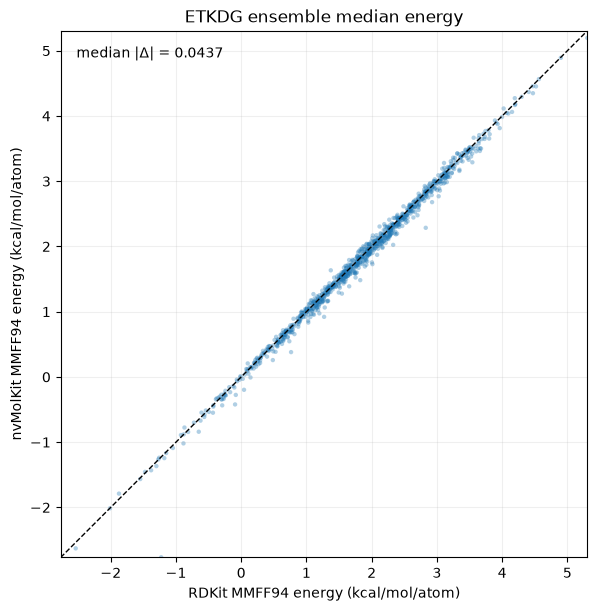

In [8]:
def mmff94_energies_per_atom(molecules):
    energy_groups = []
    for mol in molecules:
        props = AllChem.MMFFGetMoleculeProperties(mol, mmffVariant="MMFF94")
        energies = []
        for conf in mol.GetConformers():
            ff = AllChem.MMFFGetMoleculeForceField(
                mol,
                props,
                nonBondedThresh=100.0,
                confId=conf.GetId(),
                ignoreInterfragInteractions=True,
            )
            energies.append(ff.CalcEnergy() / mol.GetNumAtoms())
        energy_groups.append(np.asarray(energies))
    return energy_groups


def identity_panel(ax, x, y, title, annotation, *, full_range=False, scatter=False):
    finite = np.isfinite(x) & np.isfinite(y)
    x = np.asarray(x)[finite]
    y = np.asarray(y)[finite]
    if full_range:
        lower, upper = min(x.min(), y.min()), max(x.max(), y.max())
    else:
        lower = min(np.quantile(x, 0.001), np.quantile(y, 0.001))
        upper = max(np.quantile(x, 0.999), np.quantile(y, 0.999))
    if scatter:
        ax.scatter(x, y, s=10, alpha=0.35, edgecolors="none")
    else:
        ax.hexbin(x, y, gridsize=65, bins="log", mincnt=1, cmap="viridis")
    ax.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1)
    ax.set(xlim=(lower, upper), ylim=(lower, upper), title=title)
    ax.set_aspect("equal", adjustable="box")
    ax.text(0.03, 0.97, annotation, transform=ax.transAxes, va="top")
    ax.grid(alpha=0.2)


rdkit_etkdg_energy_groups = mmff94_energies_per_atom(rdkit_embedded)
nvmolkit_etkdg_energy_groups = mmff94_energies_per_atom(nvmolkit_embedded)
rdkit_etkdg_medians = np.asarray([np.median(x) for x in rdkit_etkdg_energy_groups])
nvmolkit_etkdg_medians = np.asarray([np.median(x) for x in nvmolkit_etkdg_energy_groups])

fig, ax = plt.subplots(figsize=(6.5, 6), constrained_layout=True)
identity_panel(
    ax,
    rdkit_etkdg_medians,
    nvmolkit_etkdg_medians,
    "ETKDG ensemble median energy",
    f"median |Δ| = {np.median(np.abs(rdkit_etkdg_medians - nvmolkit_etkdg_medians)):.3g}",
    scatter=True,
)
ax.set_xlabel("RDKit MMFF94 energy (kcal/mol/atom)")
ax.set_ylabel("nvMolKit MMFF94 energy (kcal/mol/atom)")
plt.show()

## Step 2: MMFF94 minimization

Next we minimize every conformer with MMFF94. To keep the comparison fair, all
three minimizations start from exactly the same coordinates: copies of the
conformers nvMolKit generated in step 1. Each timing includes setting up the
force field.

We run three variants:

* **RDKit**, using `MMFFOptimizeMoleculeConfs` with 16 threads and up to 200
  iterations.
* **nvMolKit BFGS**, which uses the same minimizer as RDKit, also with up to
  200 iterations.
* **nvMolKit FIRE**, an alternative minimizer that does much less work per
  step but needs more steps to converge. We give it up to 400 iterations and a
  gradient tolerance of $10^{-4}$.

Both nvMolKit runs use single precision. Like `EmbedMolecules`,
`MMFFOptimizeMoleculesConfs` takes a `precision` argument if you want double
precision instead.

In [9]:
rdkit_ff_mols = [Chem.Mol(m) for m in nvmolkit_embedded]
nvmolkit_bfgs_mols = [Chem.Mol(m) for m in nvmolkit_embedded]
nvmolkit_fire_mols = [Chem.Mol(m) for m in nvmolkit_embedded]

t0 = perf_counter()
rdkit_ff_results = [
    AllChem.MMFFOptimizeMoleculeConfs(
        mol,
        numThreads=n_cpu_threads,
        maxIters=max_mmff_iters,
        nonBondedThresh=100.0,
        ignoreInterfragInteractions=True,
    )
    for mol in rdkit_ff_mols
]
rdkit_mmff_time = perf_counter() - t0
print(f"RDKit MMFF: {rdkit_mmff_time:.2f} s")

RDKit MMFF: 67.54 s


In [10]:
t0 = perf_counter()
nvmolkit_bfgs_results = MMFFOptimizeMoleculesConfs(
    nvmolkit_bfgs_mols,
    maxIters=max_mmff_iters,
    nonBondedThreshold=100.0,
    ignoreInterfragInteractions=True,
    hardwareOptions=hardware_options,
    minimizerKind="BFGS",
    precision=gpu_precision,
)
torch.cuda.synchronize()
nvmolkit_bfgs_time = perf_counter() - t0
print(f"nvMolKit BFGS ({max_mmff_iters} iterations): {nvmolkit_bfgs_time:.2f} s")

nvMolKit BFGS (200 iterations): 8.36 s


In [11]:
fire_options = FireOptions()
fire_options.gradTol = 1e-4

t0 = perf_counter()
nvmolkit_fire_results = MMFFOptimizeMoleculesConfs(
    nvmolkit_fire_mols,
    maxIters=fire_iters,
    nonBondedThreshold=100.0,
    ignoreInterfragInteractions=True,
    hardwareOptions=hardware_options,
    minimizerKind="FIRE",
    fireOptions=fire_options,
    precision=gpu_precision,
)
torch.cuda.synchronize()
nvmolkit_fire_time = perf_counter() - t0
print(f"nvMolKit FIRE ({fire_iters} iterations): {nvmolkit_fire_time:.2f} s")

nvMolKit FIRE (400 iterations): 3.70 s


### Comparing the minimized geometries

Each minimizer reports energies from its own implementation, so to compare like
with like we re-score every final geometry with RDKit's MMFF94. Each point
below is one conformer: the x-axis is the energy after RDKit's minimization,
and the y-axis is the energy after nvMolKit's. Points on the diagonal reached
the same energy.

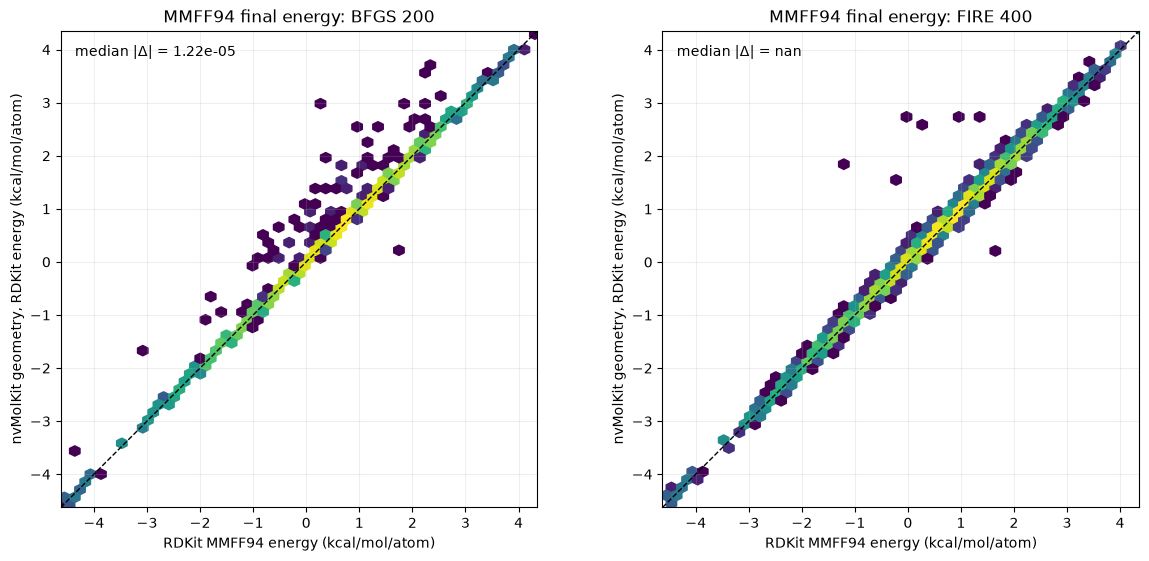

In [12]:
rdkit_final_energies = np.concatenate(mmff94_energies_per_atom(rdkit_ff_mols))
nvmolkit_bfgs_final_energies = np.concatenate(
    mmff94_energies_per_atom(nvmolkit_bfgs_mols)
)
nvmolkit_fire_final_energies = np.concatenate(
    mmff94_energies_per_atom(nvmolkit_fire_mols)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
identity_panel(
    axes[0],
    rdkit_final_energies,
    nvmolkit_bfgs_final_energies,
    f"MMFF94 final energy: BFGS {max_mmff_iters}",
    f"median |Δ| = {np.median(np.abs(rdkit_final_energies - nvmolkit_bfgs_final_energies)):.3g}",
)
identity_panel(
    axes[1],
    rdkit_final_energies,
    nvmolkit_fire_final_energies,
    f"MMFF94 final energy: FIRE {fire_iters}",
    f"median |Δ| = {np.median(np.abs(rdkit_final_energies - nvmolkit_fire_final_energies)):.3g}",
)
for ax in axes:
    ax.set_xlabel("RDKit MMFF94 energy (kcal/mol/atom)")
    ax.set_ylabel("nvMolKit geometry, RDKit energy (kcal/mol/atom)")
plt.show()

## Step 3: 3D descriptors

With minimized conformers in hand, a common next step is to describe their shapes
numerically, for example as features for a model. RDKit has a large collection of
3D descriptors, and nvMolKit implements many of them on the GPU. We'll calculate
two groups for every conformer:

* **The shape descriptors from RDKit's `Descriptors3D` module.** These are the
  principal moments of inertia (PMI1-3), the normalized PMI ratios (NPR1, NPR2),
  radius of gyration, inertial shape factor, eccentricity, asphericity,
  spherocity index, and plane of best fit (PBF). They're quick to compute and
  easy to interpret.
* **Four larger descriptor vectors:** WHIM (114 values), RDF (210),
  3D-MoRSE (224), and GETAWAY (273). These are much more expensive to calculate, and
  they're also where the GPU helps the most.

Together that's 832 numbers per conformer. RDKit's 3D descriptor functions
calculate one conformer per call and don't have a thread-count option, so on the
CPU we spread the molecules over a pool of 16 worker processes. On the GPU, a
single `Calc3DProperties` call handles every requested descriptor for every
conformer in the batch. For both, we start from the BFGS-minimized conformers
from step 2.

One gotcha we ran into while putting this together: RDKit caches a molecule's
principal axes, and `CalcPBF` will reuse that cached value even when you ask about a
different conformer. When calculating PBF for multiple conformers of the same
molecule, clear the cache with `mol.ClearComputedProps()` before each call, as
`calc_pbf` does below.

In [13]:
scalar_descriptors = [
    "PMI1",
    "PMI2",
    "PMI3",
    "NPR1",
    "NPR2",
    "RadiusOfGyration",
    "InertialShapeFactor",
    "Eccentricity",
    "Asphericity",
    "SpherocityIndex",
    "PBF",
]
vector_descriptors = ["WHIM", "RDF", "MORSE", "GETAWAY"]
descriptor_names = scalar_descriptors + vector_descriptors


def calc_pbf(mol, confId):
    # CalcPBF reuses principal axes cached on the molecule by earlier calls,
    # even for a different conformer, so clear the cache first.
    mol.ClearComputedProps()
    return rdMolDescriptors.CalcPBF(mol, confId=confId)


rdkit_descriptor_functions = {
    "PMI1": rdMolDescriptors.CalcPMI1,
    "PMI2": rdMolDescriptors.CalcPMI2,
    "PMI3": rdMolDescriptors.CalcPMI3,
    "NPR1": rdMolDescriptors.CalcNPR1,
    "NPR2": rdMolDescriptors.CalcNPR2,
    "RadiusOfGyration": rdMolDescriptors.CalcRadiusOfGyration,
    "InertialShapeFactor": rdMolDescriptors.CalcInertialShapeFactor,
    "Eccentricity": rdMolDescriptors.CalcEccentricity,
    "Asphericity": rdMolDescriptors.CalcAsphericity,
    "SpherocityIndex": rdMolDescriptors.CalcSpherocityIndex,
    "PBF": calc_pbf,
    "WHIM": rdMolDescriptors.CalcWHIM,
    "RDF": rdMolDescriptors.CalcRDF,
    "MORSE": rdMolDescriptors.CalcMORSE,
    "GETAWAY": rdMolDescriptors.CalcGETAWAY,
}


def rdkit_descriptors_for_molecule(mol):
    # Returns {descriptor name: array with one row per conformer}
    results = {}
    conf_ids = [conf.GetId() for conf in mol.GetConformers()]
    for name in descriptor_names:
        func = rdkit_descriptor_functions[name]
        results[name] = np.asarray([func(mol, confId=conf_id) for conf_id in conf_ids])
    return results


descriptor_mols = [Chem.Mol(m) for m in nvmolkit_bfgs_mols]

# Start the worker processes before timing, just like the GPU warmup.
process_pool = ProcessPoolExecutor(
    n_cpu_threads, mp_context=multiprocessing.get_context("fork")
)
list(process_pool.map(rdkit_descriptors_for_molecule, descriptor_mols[:n_cpu_threads]))
Calc3DProperties(descriptor_mols[:4], descriptor_names)[descriptor_names[0]].numpy()
torch.cuda.synchronize()

In [14]:
t0 = perf_counter()
rdkit_per_molecule = list(
    process_pool.map(rdkit_descriptors_for_molecule, descriptor_mols, chunksize=8)
)
rdkit_descriptors = {
    name: np.concatenate([r[name] for r in rdkit_per_molecule]).reshape(-1, 1)
    if name in scalar_descriptors
    else np.concatenate([r[name] for r in rdkit_per_molecule])
    for name in descriptor_names
}
rdkit_descriptor_time = perf_counter() - t0
process_pool.shutdown()
print(f"RDKit 3D descriptors: {rdkit_descriptor_time:.2f} s")

RDKit 3D descriptors: 8.33 s


In [15]:
t0 = perf_counter()
nvmolkit_descriptor_results = Calc3DProperties(
    descriptor_mols, descriptor_names, hardwareOptions=hardware_options
)
nvmolkit_descriptors = {
    name: nvmolkit_descriptor_results[name].numpy().reshape(
        nvmolkit_descriptor_results.n_conformers, -1
    )
    for name in descriptor_names
}
nvmolkit_descriptor_time = perf_counter() - t0
print(f"nvMolKit 3D descriptors: {nvmolkit_descriptor_time:.3f} s")
print(
    f"{nvmolkit_descriptor_results.n_conformers:,} conformers x "
    f"{sum(v.shape[1] for v in nvmolkit_descriptors.values())} values"
)

nvMolKit 3D descriptors: 0.077 s
49,950 conformers x 832 values


`Calc3DProperties` computes in single precision by default, which is plenty for
descriptors that are mostly used as model features. Pass
`precision=PrecisionMode.FULL` if you want results that match RDKit to
double-precision rounding.

### Do the descriptors agree?

The rows of both results are in the same order (molecule, then conformer), so we
can compare them value by value. The table below lists, for each descriptor, the
fraction of values that agree with RDKit to within a relative tolerance of
$10^{-3}$ (or an absolute tolerance of $10^{-3}$ for values near zero), along
with the largest absolute difference.

In [16]:
agreement = []
for name in descriptor_names:
    ref = rdkit_descriptors[name]
    gpu = nvmolkit_descriptors[name].astype(np.float64)
    finite = np.isfinite(ref) & np.isfinite(gpu)
    close = np.isclose(gpu[finite], ref[finite], rtol=1e-3, atol=1e-3)
    agreement.append(
        {
            "descriptor": name,
            "values per conformer": ref.shape[1],
            "within tolerance": close.mean(),
            "max |Δ|": np.abs(gpu[finite] - ref[finite]).max(),
        }
    )
agreement = pd.DataFrame(agreement).set_index("descriptor")
agreement.style.format({"within tolerance": "{:.3%}", "max |Δ|": "{:.2g}"})

,values per conformer,within tolerance,max |Δ|
descriptor,,,
PMI1,1,100.000%,0.0023
PMI2,1,100.000%,0.0033
PMI3,1,100.000%,0.0035
NPR1,1,100.000%,2.5e-07
NPR2,1,100.000%,4e-07
RadiusOfGyration,1,100.000%,8.7e-07
InertialShapeFactor,1,100.000%,3.6e-09
Eccentricity,1,100.000%,2.9e-07
Asphericity,1,100.000%,4.6e-07


A more familiar view of the same data is the normalized PMI plot, which places
every conformer in a triangle whose corners are rod-like, disc-like, and
sphere-like shapes. If the GPU values are right, the two panels should look the
same.

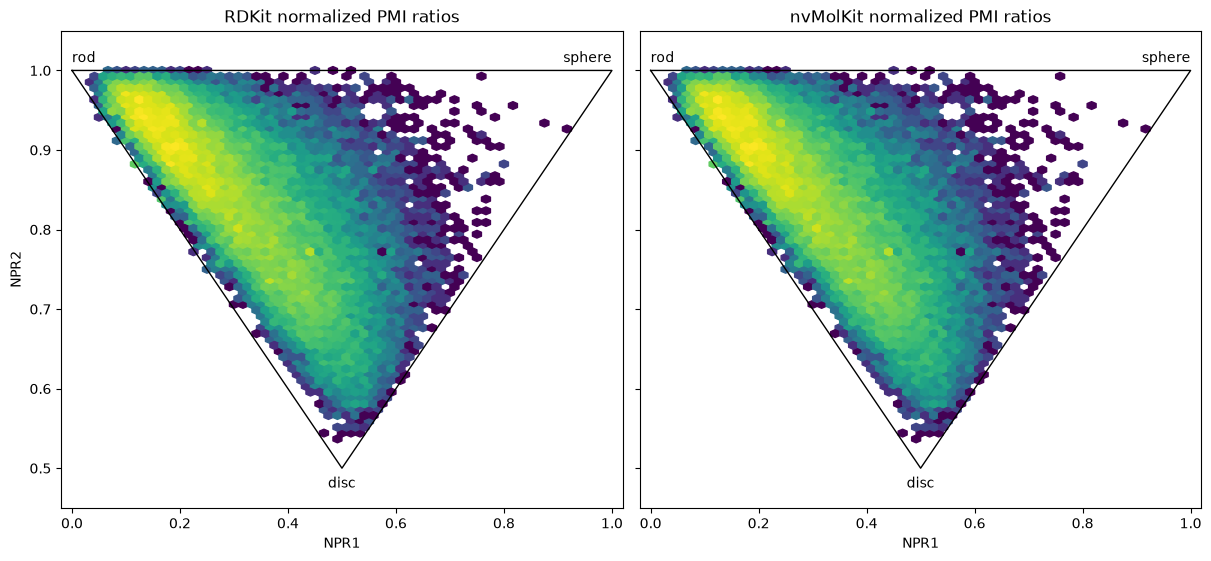

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True, constrained_layout=True)
for ax, label, values in zip(
    axes, ["RDKit", "nvMolKit"], [rdkit_descriptors, nvmolkit_descriptors]
):
    ax.hexbin(
        values["NPR1"].ravel(),
        values["NPR2"].ravel(),
        gridsize=60,
        bins="log",
        mincnt=1,
        cmap="viridis",
        extent=(0, 1, 0.5, 1),
    )
    ax.plot([0, 0.5, 1, 0], [1, 0.5, 1, 1], color="black", linewidth=1)
    for x, y, text, ha in [(0, 1, "rod", "left"), (0.5, 0.5, "disc", "center"), (1, 1, "sphere", "right")]:
        ax.annotate(text, (x, y), textcoords="offset points", xytext=(0, 6 if y == 1 else -14), ha=ha)
    ax.set(title=f"{label} normalized PMI ratios", xlabel="NPR1", xlim=(-0.02, 1.02), ylim=(0.45, 1.05))
axes[0].set_ylabel("NPR2")
plt.show()

## Step 4: TFD matrices and conformer pruning

Fifty conformers per molecule usually includes a lot of near-duplicates. A common
way to prune them is to cluster each molecule's conformers by torsion fingerprint
deviation (TFD), which measures how different two conformers' rotatable-bond
torsions are. Because it only looks at torsions, TFD doesn't depend on how the
conformers are aligned.

Both implementations calculate the full TFD matrix for each molecule from the same
BFGS-minimized conformers, with explicit hydrogens removed.

RDKit TFD: 3.28 s
nvMolKit TFD: 0.011 s
TFD values within 0.01: 99.56%


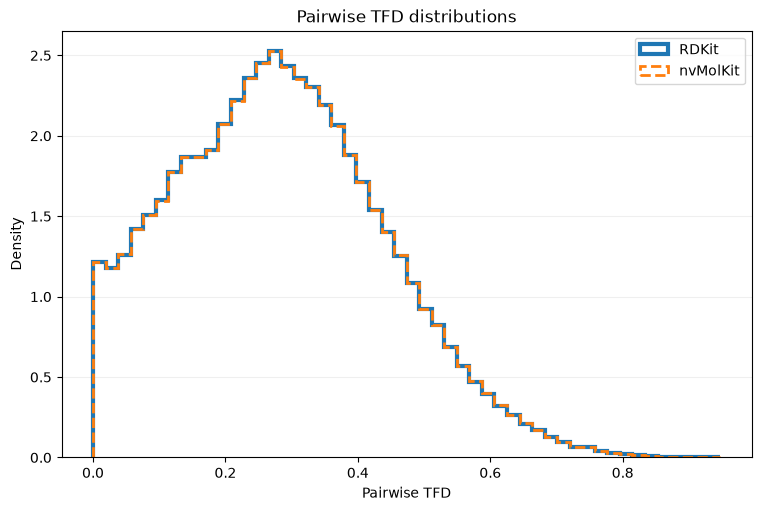

In [18]:
rdkit_tfd_mols = [Chem.RemoveHs(Chem.Mol(m)) for m in nvmolkit_bfgs_mols]
nvmolkit_tfd_mols = [Chem.Mol(m) for m in rdkit_tfd_mols]

t0 = perf_counter()
nvmolkit_tfd_results = GetTFDMatrices(nvmolkit_tfd_mols, return_type="numpy")
torch.cuda.synchronize()
nvmolkit_tfd_time = perf_counter() - t0

t0 = perf_counter()
rdkit_tfd_results = [
    TorsionFingerprints.GetTFDMatrix(mol, useWeights=True, maxDev="equal")
    for mol in rdkit_tfd_mols
]
rdkit_tfd_time = perf_counter() - t0

tfd_pairs = [
    (np.asarray(rd), np.asarray(nv))
    for rd, nv in zip(rdkit_tfd_results, nvmolkit_tfd_results)
    if len(rd)
]
rdkit_tfd_values = np.concatenate([rd for rd, _ in tfd_pairs])
nvmolkit_tfd_values = np.concatenate([nv for _, nv in tfd_pairs])
tfd_abs_differences = np.abs(rdkit_tfd_values - nvmolkit_tfd_values)
print(f"RDKit TFD: {rdkit_tfd_time:.2f} s")
print(f"nvMolKit TFD: {nvmolkit_tfd_time:.3f} s")
print(f"TFD values within 0.01: {np.mean(tfd_abs_differences <= 0.01):.2%}")

tfd_histogram_bins = np.linspace(
    min(rdkit_tfd_values.min(), nvmolkit_tfd_values.min()),
    max(rdkit_tfd_values.max(), nvmolkit_tfd_values.max()),
    51,
)
fig, ax = plt.subplots(figsize=(7.5, 5), constrained_layout=True)
ax.hist(
    rdkit_tfd_values,
    bins=tfd_histogram_bins,
    density=True,
    histtype="step",
    linewidth=3,
    label="RDKit",
)
ax.hist(
    nvmolkit_tfd_values,
    bins=tfd_histogram_bins,
    density=True,
    histtype="step",
    linewidth=2,
    linestyle="--",
    label="nvMolKit",
)
ax.set(
    xlabel="Pairwise TFD",
    ylabel="Density",
    title="Pairwise TFD distributions",
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
plt.show()

The distributions overlap, but small numerical differences only matter if they
change a decision. To check, we feed each implementation's TFD matrices into
Butina clustering with a 0.10 cutoff, and keep one representative conformer per
cluster. Then we compare how many conformers each version keeps, and whether it
picks the same ones.

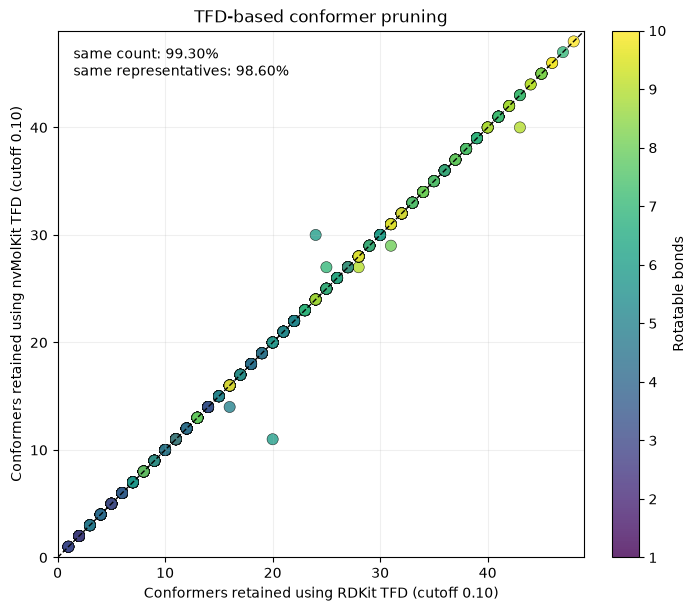

In [19]:
tfd_pruning_cutoff = 0.10
tfd_pruning_data = []
for mol, rdkit_distances, nvmolkit_distances in zip(
    rdkit_tfd_mols, rdkit_tfd_results, nvmolkit_tfd_results
):
    rdkit_distances = np.asarray(rdkit_distances)
    nvmolkit_distances = np.asarray(nvmolkit_distances)
    if not len(rdkit_distances):
        continue

    n = mol.GetNumConformers()
    rdkit_clusters = Butina.ClusterData(
        rdkit_distances, n, tfd_pruning_cutoff, isDistData=True
    )
    nvmolkit_clusters = Butina.ClusterData(
        nvmolkit_distances, n, tfd_pruning_cutoff, isDistData=True
    )
    tfd_pruning_data.append(
        {
            "rdkit_count": len(rdkit_clusters),
            "nvmolkit_count": len(nvmolkit_clusters),
            "same_representatives": {cluster[0] for cluster in rdkit_clusters}
            == {cluster[0] for cluster in nvmolkit_clusters},
            "n_rotors": rdMolDescriptors.CalcNumRotatableBonds(mol),
        }
    )

rdkit_retained = np.asarray([item["rdkit_count"] for item in tfd_pruning_data])
nvmolkit_retained = np.asarray([item["nvmolkit_count"] for item in tfd_pruning_data])
rotor_counts = np.asarray([item["n_rotors"] for item in tfd_pruning_data])
same_count = rdkit_retained == nvmolkit_retained
same_representatives = np.asarray(
    [item["same_representatives"] for item in tfd_pruning_data]
)

lower = min(rdkit_retained.min(), nvmolkit_retained.min()) - 1
upper = max(rdkit_retained.max(), nvmolkit_retained.max()) + 1
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
points = ax.scatter(
    rdkit_retained,
    nvmolkit_retained,
    c=rotor_counts,
    cmap="viridis",
    s=65,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4,
)
ax.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1)
ax.set(
    xlim=(lower, upper),
    ylim=(lower, upper),
    xlabel=f"Conformers retained using RDKit TFD (cutoff {tfd_pruning_cutoff:.2f})",
    ylabel=f"Conformers retained using nvMolKit TFD (cutoff {tfd_pruning_cutoff:.2f})",
    title="TFD-based conformer pruning",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.text(
    0.03,
    0.97,
    f"same count: {same_count.mean():.2%}\n"
    f"same representatives: {same_representatives.mean():.2%}",
    transform=ax.transAxes,
    va="top",
)
fig.colorbar(points, ax=ax, label="Rotatable bonds")
plt.show()

## Performance comparison

Now for the timings. The workflow total is the sum of the four timed steps. Loading
molecules, making copies, warmup, the validation re-scoring, and plotting aren't
included. The ETKDG, descriptor, and TFD steps are shared between the two GPU
columns. Only the minimizer differs.

In [20]:
timings = pd.DataFrame(
    {
        "RDKit": [
            rdkit_embed_time,
            rdkit_mmff_time,
            rdkit_descriptor_time,
            rdkit_tfd_time,
        ],
        f"nvMolKit BFGS {max_mmff_iters}": [
            nvmolkit_embed_time,
            nvmolkit_bfgs_time,
            nvmolkit_descriptor_time,
            nvmolkit_tfd_time,
        ],
        f"nvMolKit FIRE {fire_iters}": [
            nvmolkit_embed_time,
            nvmolkit_fire_time,
            nvmolkit_descriptor_time,
            nvmolkit_tfd_time,
        ],
    },
    index=["ETKDG", "MMFF94", "3D descriptors", "TFD"],
)
timings.loc["Total"] = timings.sum()
speedups = timings["RDKit"].to_numpy()[:, None] / timings
timings.style.format("{:.2f} s").set_caption("Wall-clock time")

,RDKit,nvMolKit BFGS 200,nvMolKit FIRE 400
ETKDG,111.15 s,19.59 s,19.59 s
MMFF94,67.54 s,8.36 s,3.70 s
3D descriptors,8.33 s,0.08 s,0.08 s
TFD,3.28 s,0.01 s,0.01 s
Total,190.31 s,28.04 s,23.38 s


In [21]:
speedups.style.format("{:.1f}x").set_caption("Speedup vs RDKit")

,RDKit,nvMolKit BFGS 200,nvMolKit FIRE 400
ETKDG,1.0x,5.7x,5.7x
MMFF94,1.0x,8.1x,18.2x
3D descriptors,1.0x,107.5x,107.5x
TFD,1.0x,300.7x,300.7x
Total,1.0x,6.8x,8.1x


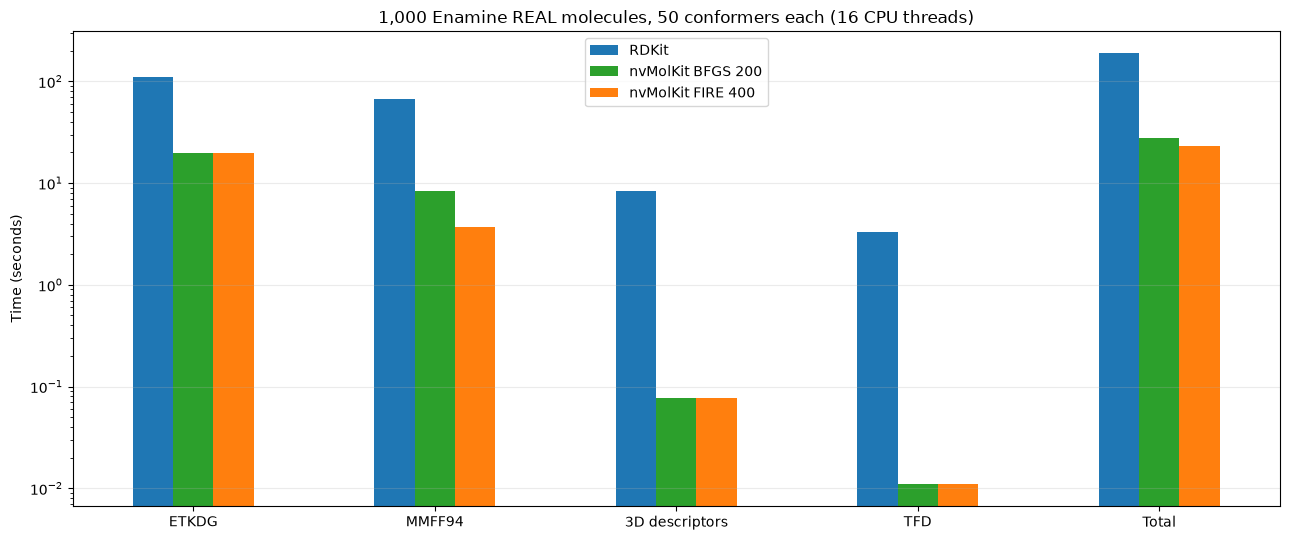

In [22]:
ax = timings.plot.bar(
    figsize=(13, 5.5),
    color=["#1f77b4", "#2ca02c", "#ff7f0e"],
)
ax.set_ylabel("Time (seconds)")
ax.set_yscale("log")
ax.set_title(
    f"{n_mols:,} Enamine REAL molecules, {n_confs} conformers each "
    f"({n_cpu_threads} CPU threads)"
)
ax.set_xticklabels(timings.index, rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

On our test machine, the full GPU workflow runs about 7x faster than RDKit with
BFGS and about 8x faster with FIRE. ETKDG takes most of the time on both sides,
so it largely sets the overall speedup. The descriptor and TFD steps barely
register on the GPU. They drop from several seconds to tens of milliseconds, which
makes it cheap to calculate many more descriptors, or to calculate them for many
more conformers.

Single precision makes a big difference here. When we reran the GPU stages
with `PrecisionMode.FULL`, ETKDG took 45 s instead of 19 s, BFGS took 21 s instead
of 8 s, and FIRE took 18 s instead of 4 s. That's still roughly 3x faster than
RDKit end to end. The gap between the two modes is especially large on consumer
GPUs like this one, which have relatively little double-precision hardware.
Datacenter GPUs narrow it considerably.

## Appendix: choosing the FIRE iteration budget

FIRE does much less work per step than BFGS, but on drug-like molecules it
usually needs more steps to reach the same energy. That makes the iteration
limit a speed-versus-fidelity knob. The right setting depends on what you need
the geometries for, so it's worth measuring on your own data.

To pick a value for this post, we ran FIRE with 200, 400, and 600 iterations on a
separate set of 500 Enamine REAL molecules with 50 conformers each. Every run
started from the same nvMolKit ETKDG coordinates, used single precision, and all
final geometries were re-scored with RDKit's MMFF94. We compare against nvMolKit
BFGS with 200 iterations.

| FIRE iterations | FIRE time | FIRE lower | median $\Delta E$ | median $|\Delta E|$ | $|\Delta E| \le 10^{-4}$ | $|\Delta E| \le 10^{-3}$ |
|---:|---:|---:|---:|---:|---:|---:|
| 200 | 0.26 s | 1.7% | 7.1e-3 | 7.5e-3 | 8.6% | 24.4% |
| 400 | 0.45 s | 15.3% | 5.7e-5 | 9.2e-5 | 50.6% | 66.9% |
| 600 | 0.63 s | 43.3% | 1.3e-7 | 1.1e-6 | 75.1% | 82.5% |

BFGS took 1.29 s on the same 25,000 conformers.

$\Delta E$ is `(FIRE - BFGS) / atom` in kcal/mol, so negative values mean
FIRE found the lower energy. "FIRE lower" is the fraction of conformers where
that happened.

At 200 iterations, FIRE hasn't finished the job: most conformers are still
noticeably above the BFGS energy. By 400 iterations the median difference is
below $10^{-4}$ kcal/mol/atom, and at 600 the two minimizers are essentially
indistinguishable, with FIRE finding the lower energy almost half the time. We
went with 400 iterations as a reasonable middle ground, which is still about 3x
faster than BFGS. If your application needs tighter minimization, 600 is a good
choice and is still about twice as fast.

![FIRE versus BFGS final energies](images/nvmolkit_fire_energy_vs_energy.png)

![FIRE minus BFGS energy distributions](images/nvmolkit_fire_energy_difference_histograms.png)

The histograms show the central 99% of each distribution. Outliers are
left out of the plotted range only, and are still counted in the table.